# Exploratory Data Analysis — CUB-200-2011 Tabular Attributes (R2)

This notebook explores the prepared attribute data **before** modelling: what the attributes look like, how they relate
to each other and to the species, and why separating 200 species is hard. Each section ends with a short **takeaway**
for the report.

**Input:** `data/cub_features_A.csv` from [`dataPrep.ipynb`](dataPrep.ipynb) (run that first), plus the photos and
bounding boxes in `CUB_200_2011/` for the examples.
**Output:** figures in `documentation/figures/` (prefix `eda_`). No data is changed.

EDA is descriptive and uses all 11,788 images. Anything that decides how a model is built (feature selection) uses the
training split only, in [`featureSelection.ipynb`](featureSelection.ipynb).

| Step | Section |
|---|---|
| Two examples from the datasets | 2 |
| How many attributes describe each bird? | 3 |
| Attribute values within groups | 4 |
| Species × attribute profiles | 5 |
| Correlation between attributes (redundancy) | 6 |
| Which species look alike? | 7 |
| PCA: how much structure is there? | 8 |
| Key findings | 9 |

## 1. Setup

In [1]:
# --- GenAI disclosure (F20DL coursework spec, Section 8) ---
# This notebook was drafted with Claude (Anthropic) in a guided conversation, then reviewed,
# run and checked by Muhammad Faizal Haris bin Aidi. Main prompts used:
# 1. "deeply analyse everything ... then later im gonna need your help in finishing this"
# 2. "lets do R2 to the best we can fully following the requirements and course contents"
# 3. "trim it down ... fully following what the course teaches"
# 4. "basically we gonna use [Ryan's data prep] for this, but add whats needed/not available yet"

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
SPLIT = 'is_train'  # official split, same as the main model notebooks
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
FIGURES = ROOT / 'documentation' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train', 'is_train_80']  # never used as features

# One consistent look for every figure
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'font.size': 9, 'legend.frameon': False})
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

def load_features(variant='A'):
    """Feature table written by dataPrep.ipynb (variant A = raw 0/1 attributes)."""
    path = DATA / f'cub_features_{variant}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    df = pd.read_csv(path).copy()   # .copy() keeps the 300+ columns in one memory block
    df['species'] = df.class_name.str.split('.', n=1).str[1].str.replace('_', ' ')
    return df.copy()

def save_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png')

# Dataset folder, found the same way as in dataPrep.ipynb: inside data/raw/, or CUB_200_2011/ at the repo root
CUB = next((p.parent for p in (ROOT / 'data' / 'raw').rglob('image_class_labels.txt')), ROOT / 'CUB_200_2011')
assert CUB.exists(), 'Dataset not found - see README "Getting the data"'

import matplotlib.patches as patches
from PIL import Image

df = load_features('A')
ATTR = [c for c in df.columns if c not in META_COLS + ['species']]
GROUP = pd.Series({c: c.split('::')[0].replace('has_', '') for c in ATTR})   # attribute -> its group
df['name_group'] = df.species.str.split().str[-1]   # last word of the name, only to label plots

images = (pd.read_csv(CUB / 'images.txt', sep=r'\s+', header=None, names=['image_id', 'path'])
            .merge(pd.read_csv(CUB / 'bounding_boxes.txt', sep=r'\s+', header=None,
                               names=['image_id', 'x', 'y', 'w', 'h']))
            .set_index('image_id'))

print(f'{len(df):,} images | {df.class_id.nunique()} species | {len(ATTR)} attributes in {GROUP.nunique()} groups')

11,788 images | 200 species | 312 attributes in 28 groups


## 2. Two examples from the datasets

Each photo has a bounding box around the bird (the image dataset); the same photo is described by the binary attributes
that the annotator marked as present (the tabular dataset).

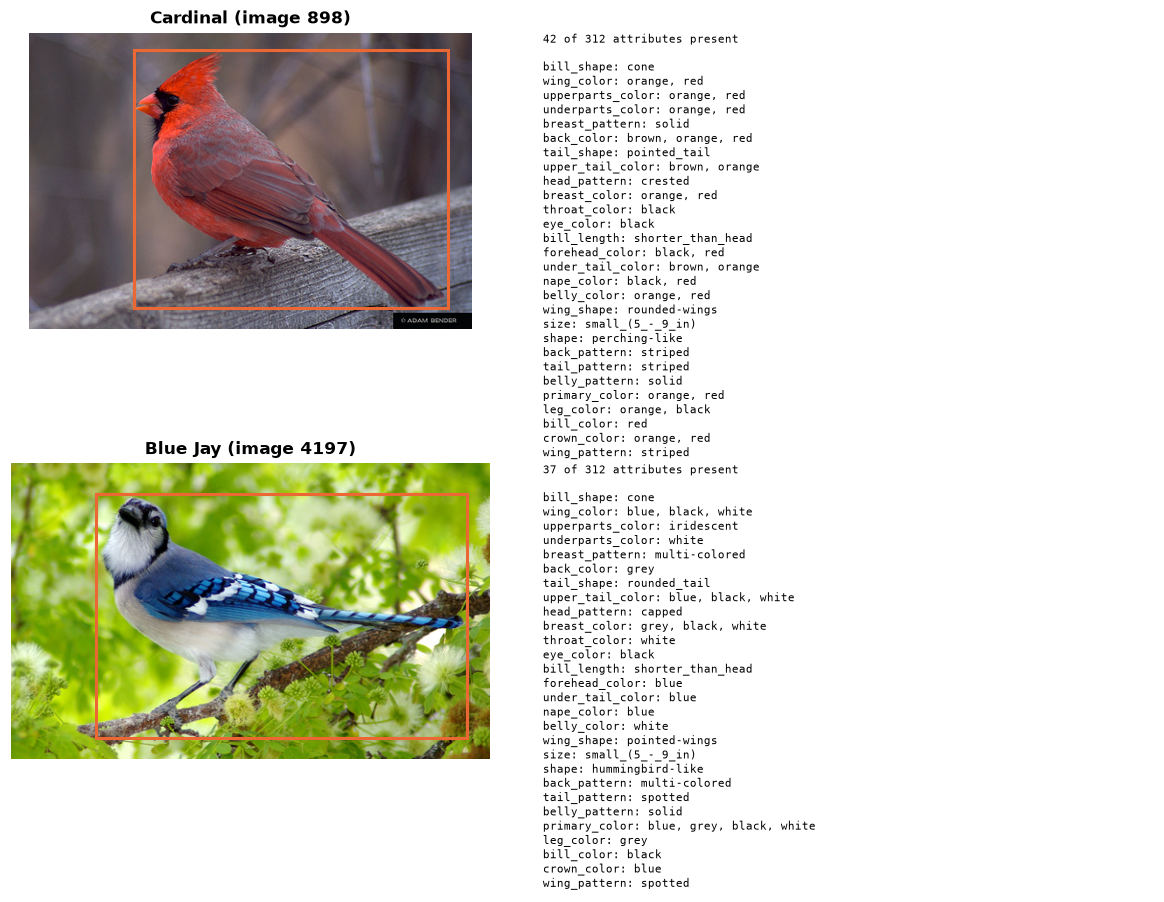

In [2]:
def first_train_image(species):
    return int(df[(df.species == species) & (df[SPLIT] == 1)].image_id.min())

def show_example(ax_img, ax_txt, image_id):
    # Left: the photo with its bounding box. Right: the attributes marked present, by group.
    meta = images.loc[image_id]
    ax_img.imshow(Image.open(CUB / 'images' / meta.path).convert('RGB'))
    ax_img.add_patch(patches.Rectangle((meta.x, meta.y), meta.w, meta.h, fill=False, edgecolor=ORANGE, linewidth=2))
    ax_img.set_title(f"{df.loc[df.image_id == image_id, 'species'].iloc[0]} (image {image_id})")
    ax_img.axis('off')

    row = df.loc[df.image_id == image_id, ATTR].iloc[0]
    present = [c for c in ATTR if row[c] == 1]
    lines = {}
    for c in present:
        lines.setdefault(GROUP[c], []).append(c.split('::')[1])
    text = '\n'.join(f"{g}: {', '.join(v)}" for g, v in lines.items())
    ax_txt.text(0, 1, f'{len(present)} of 312 attributes present\n\n{text}', va='top', fontsize=7.5, family='monospace')
    ax_txt.axis('off')

fig, axes = plt.subplots(2, 2, figsize=(11, 8), gridspec_kw={'width_ratios': [1, 1.1]})
for r, species in enumerate(['Cardinal', 'Blue Jay']):
    show_example(axes[r, 0], axes[r, 1], first_train_image(species))
plt.tight_layout()
save_figure(fig, 'eda_examples')
plt.show()

**Takeaway:** each bird is described by a few dozen present attributes. The labels are useful but **noisy**: this Blue
Jay is labelled with a *hummingbird-like* shape and the Cardinal with a *brown* back. The box shows the bird often fills
only part of the photo.

## 3. How many attributes describe each bird?

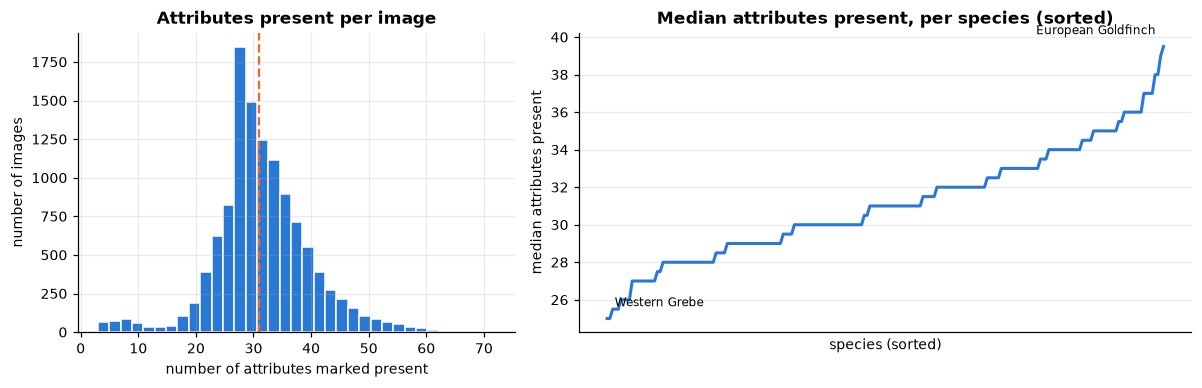

,count,mean,std,min,25%,50%,75%,max
attributes present,11788.0,31.5,8.5,3.0,27.0,31.0,36.0,72.0


In [3]:
n_present = df[ATTR].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1, 1.4]})
axes[0].hist(n_present, bins=35, color=BLUE, edgecolor='white')
axes[0].axvline(n_present.median(), color=ORANGE, ls='--')
axes[0].set(title='Attributes present per image', xlabel='number of attributes marked present', ylabel='number of images')

per_species = n_present.groupby(df.species).median().sort_values()
axes[1].plot(np.arange(len(per_species)), per_species.values, color=BLUE, lw=2)
for i in [0, len(per_species) - 1]:
    axes[1].annotate(per_species.index[i], (i, per_species.iloc[i]), fontsize=8,
                     xytext=(5 if i == 0 else -5, 8), textcoords='offset points', ha='left' if i == 0 else 'right')
axes[1].set(title='Median attributes present, per species (sorted)', xlabel='species (sorted)',
            ylabel='median attributes present', xticks=[])
plt.tight_layout()
save_figure(fig, 'eda_attributes_per_image')
plt.show()

n_present.describe().round(1).to_frame('attributes present').T

**Takeaway:** an image has about 31 of the 312 attributes present (only ~10%), so the data is **sparse**. Colourful,
patterned species get many more attributes than plain ones, so distance-based methods (k-NN, K-Means) will see plain
birds as "close" to each other simply because they share many zeros.

## 4. Attribute values within groups

The 312 attributes come from 28 groups such as `primary_color` (15 colours) or `shape` (14 shapes). Four groups that
describe the whole bird:

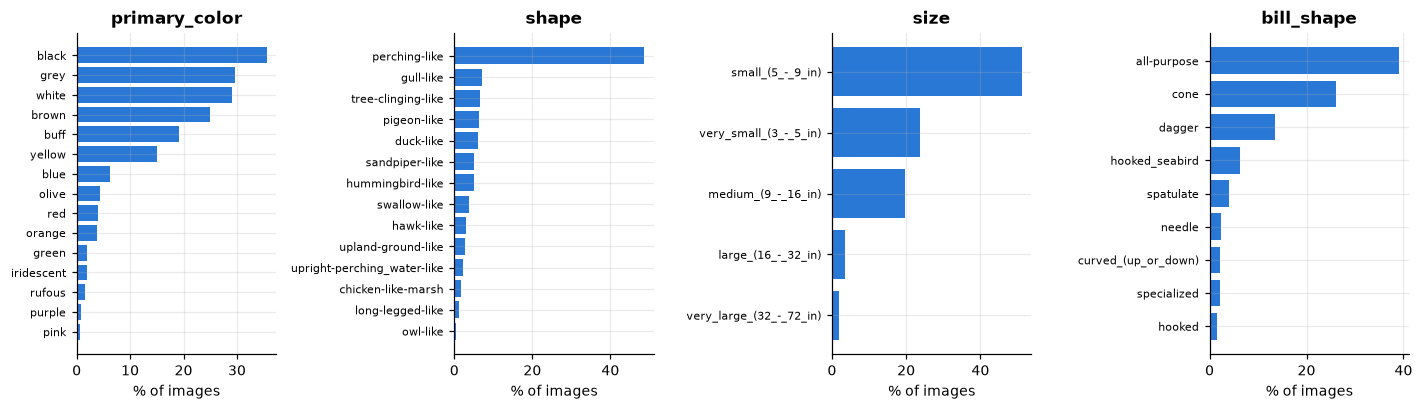

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for ax, g in zip(axes, ['primary_color', 'shape', 'size', 'bill_shape']):
    cols = GROUP[GROUP == g].index
    share = (df[cols].mean() * 100).sort_values()
    ax.barh([c.split('::')[1] for c in share.index], share.values, color=BLUE)
    ax.set(title=g, xlabel='% of images')
    ax.tick_params(axis='y', labelsize=7)
plt.tight_layout()
save_figure(fig, 'eda_group_values')
plt.show()

**Takeaway:** most birds are small, perching-like, with black/white/grey/brown plumage and a cone or all-purpose bill, so
the dataset is dominated by songbirds. Rare values (green, purple, needle bill) belong to a few species only.

## 5. Species × attribute profiles

A species **profile** is the share of its images that have each attribute. Below: two warblers, two sparrows, two gulls
and two terns, on the 25 attributes that vary most between them.

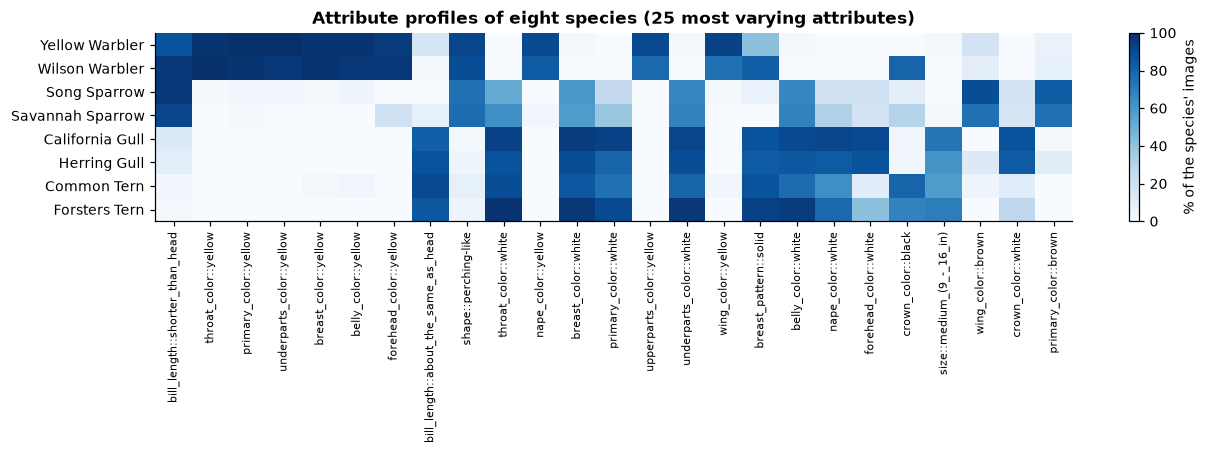

In [5]:
profiles = df.groupby('species')[ATTR].mean()

chosen = ['Yellow Warbler', 'Wilson Warbler', 'Song Sparrow', 'Savannah Sparrow',
          'California Gull', 'Herring Gull', 'Common Tern', 'Forsters Tern']
sub = profiles.loc[chosen]
top_attrs = sub.var().sort_values(ascending=False).index[:25]

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(sub[top_attrs].values * 100, cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(len(top_attrs)), [c.replace('has_', '') for c in top_attrs], rotation=90, fontsize=7)
ax.set_yticks(range(len(chosen)), chosen)
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of the species' images")
ax.set_title('Attribute profiles of eight species (25 most varying attributes)')
plt.tight_layout()
save_figure(fig, 'eda_species_profiles')
plt.show()

**Takeaway:** different *kinds* of bird (warbler vs gull) have clearly different profiles, but species of the same kind
(California vs Herring Gull, Common vs Forster's Tern) look almost identical. No attribute is present in 100% of a
species' images: each species is a cloud of slightly different vectors, not one fixed vector.

## 6. Correlation between attributes

All attributes are binary, so Pearson's *r* computed on 0/1 data (also called the **phi coefficient**) is the right
association measure (Lecture 4: choose the measure that matches the data types). Strong correlations mean **redundant**
attributes, which carry the same information twice.

In [6]:
corr = df[ATTR].corr()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename('phi').reset_index()
pairs.columns = ['attribute A', 'attribute B', 'phi']

print(f"Pairs with |phi| > 0.5: {(pairs.phi.abs() > 0.5).sum()} of {len(pairs):,}")
pairs.reindex(pairs.phi.abs().sort_values(ascending=False).index).head(10).round(3)

Pairs with |phi| > 0.5: 400 of 97,344


,attribute A,attribute B,phi
14243,has_underparts_color::yellow,has_belly_color::yellow,0.907
16121,has_underparts_color::white,has_belly_color::white,0.881
14151,has_underparts_color::yellow,has_breast_color::yellow,0.856
47717,has_forehead_color::blue,has_crown_color::blue,0.854
14556,has_underparts_color::olive,has_belly_color::olive,0.846
34835,has_breast_color::yellow,has_belly_color::yellow,0.840
16434,has_underparts_color::red,has_belly_color::red,0.837
48030,has_forehead_color::brown,has_crown_color::brown,0.825
46639,has_bill_length::about_the_same_as_head,has_bill_length::shorter_than_head,-0.824
2832,has_wing_color::blue,has_upperparts_color::blue,0.824


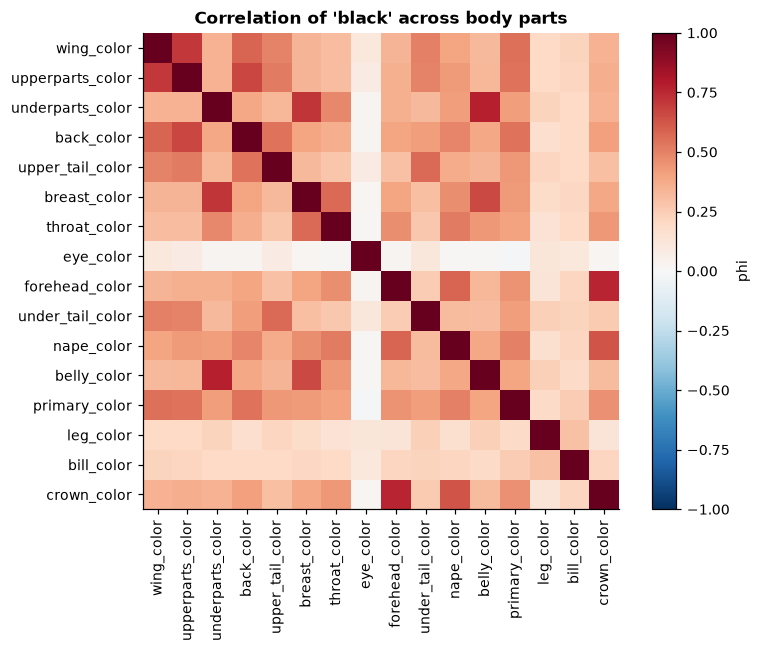

In [7]:
# Example of redundancy: the colour 'black' recorded separately for 14 body parts
black = [c for c in ATTR if c.endswith('::black')]
labels = [GROUP[c] for c in black]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.loc[black, black].values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(black)), labels, rotation=90)
ax.set_yticks(range(len(black)), labels)
ax.grid(False)
fig.colorbar(im, ax=ax, label='phi')
ax.set_title("Correlation of 'black' across body parts")
plt.tight_layout()
save_figure(fig, 'eda_black_correlation')
plt.show()

**Takeaway:** the strongest correlations are the **same colour on neighbouring body parts** (belly / breast / underparts,
upperparts / back / wing). These attributes are partly redundant. This motivates the redundancy check in
`featureSelection.ipynb`, and it breaks Naive Bayes' assumption that features are independent.

## 7. Which species look alike?

We measure the **Euclidean distance** between species profiles, the same distance k-NN uses (Lecture 3). A small distance
means two species are described almost the same way: those are the pairs any classifier will struggle with.

In [8]:
from sklearn.metrics.pairwise import euclidean_distances

dist = pd.DataFrame(euclidean_distances(profiles), index=profiles.index, columns=profiles.index)
iu = np.triu_indices(len(dist), k=1)                       # every pair of species once
pairs_dist = pd.DataFrame({'species A': dist.index[iu[0]], 'species B': dist.columns[iu[1]],
                           'distance': dist.values[iu]})
closest = pairs_dist.sort_values('distance').reset_index(drop=True)

typical = pairs_dist.distance.median()                      # distance between two typical species
nearest = dist.where(~np.eye(len(dist), dtype=bool)).min()  # each species' closest other species
print(f'Typical distance between two species: {typical:.2f}')
print(f'Species whose closest neighbour is less than half that distance away: {(nearest < typical / 2).sum()} of 200')
closest.head(10).round(3)

Typical distance between two species: 3.40
Species whose closest neighbour is less than half that distance away: 127 of 200


,species A,species B,distance
0,American Crow,Fish Crow,0.646
1,Common Raven,Fish Crow,0.711
2,American Crow,Common Raven,0.807
3,Great Grey Shrike,Loggerhead Shrike,0.838
4,Long tailed Jaeger,Pomarine Jaeger,0.939
5,Blue Grosbeak,Indigo Bunting,0.942
6,Caspian Tern,Elegant Tern,0.948
7,Brewer Blackbird,Shiny Cowbird,0.951
8,Groove billed Ani,Shiny Cowbird,0.965
9,California Gull,Herring Gull,0.976


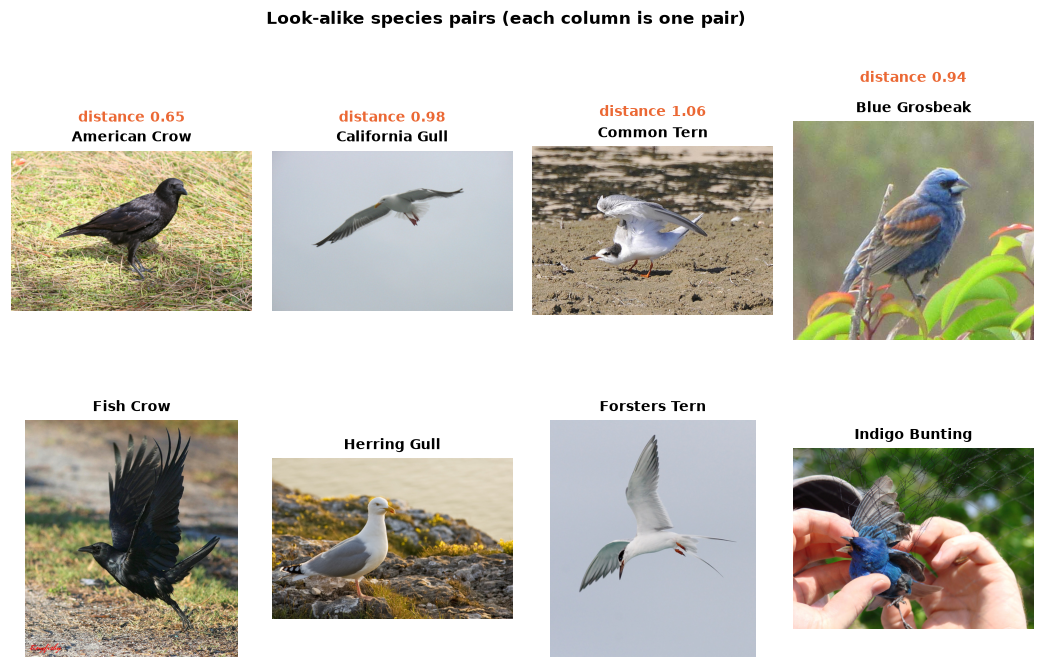

In [9]:
look_alikes = [('American Crow', 'Fish Crow'), ('California Gull', 'Herring Gull'),
               ('Common Tern', 'Forsters Tern'), ('Blue Grosbeak', 'Indigo Bunting')]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.6))
for col, pair in enumerate(look_alikes):
    for row, species in enumerate(pair):
        meta = images.loc[first_train_image(species)]
        axes[row, col].imshow(Image.open(CUB / 'images' / meta.path).convert('RGB'))
        axes[row, col].set_title(species, fontsize=9)
        axes[row, col].axis('off')
    axes[0, col].text(0.5, 1.18, f"distance {dist.loc[pair[0], pair[1]]:.2f}", transform=axes[0, col].transAxes,
                      ha='center', fontsize=9, color=ORANGE, fontweight='bold')
fig.suptitle('Look-alike species pairs (each column is one pair)', fontweight='bold', y=1.0)
fig.subplots_adjust(hspace=0.3, wspace=0.08, top=0.86)
save_figure(fig, 'eda_look_alikes')
plt.show()

**Takeaway:** many species have a close look-alike (crows and raven, gulls, terns, blue finches). This is the core
difficulty of **fine-grained** classification. It matches the errors in the decision tree and random forest notebooks
(crows, Blue Grosbeak vs Indigo Bunting), so it explains in advance why accuracy on 200 species stays well below 100%.

## 8. PCA: how much structure is there?

Principal Component Analysis (Lecture 8) finds the directions of largest variance: how many directions carry the
information, and what a 2-D picture of the data looks like.

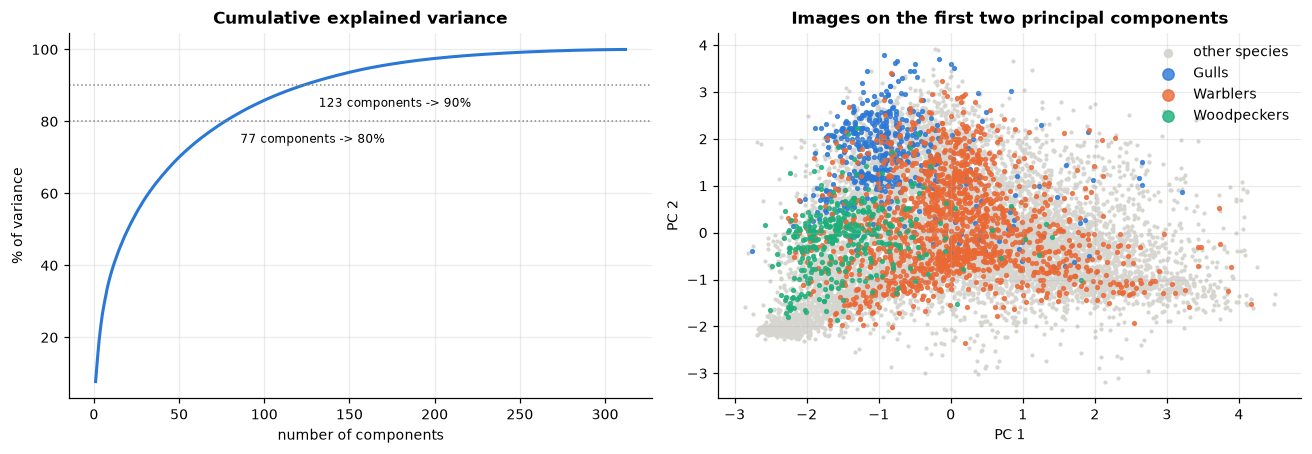

PC1 + PC2 explain 13.6% of the variance; 80% needs 77 components, 90% needs 123.


In [10]:
from sklearn.decomposition import PCA

pca = PCA(random_state=RANDOM_STATE).fit(df[ATTR].values)
cum = np.cumsum(pca.explained_variance_ratio_)
n80, n90 = np.searchsorted(cum, 0.80) + 1, np.searchsorted(cum, 0.90) + 1
Z = pca.transform(df[ATTR].values)[:, :2]
highlight = {'Gull': BLUE, 'Warbler': ORANGE, 'Woodpecker': AQUA}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(np.arange(1, len(cum) + 1), cum * 100, color=BLUE, lw=2)
for n, level in [(n80, 80), (n90, 90)]:
    axes[0].axhline(level, color=GREY, ls=':', lw=1)
    axes[0].annotate(f'{n} components -> {level}%', (n, level), xytext=(10, -14), textcoords='offset points', fontsize=8)
axes[0].set(title='Cumulative explained variance', xlabel='number of components', ylabel='% of variance')

others = ~df.name_group.isin(highlight)
axes[1].scatter(Z[others, 0], Z[others, 1], s=3, color='#d6d5d0', label='other species')
for group, colour in highlight.items():
    m = (df.name_group == group).values
    axes[1].scatter(Z[m, 0], Z[m, 1], s=6, color=colour, label=f'{group}s', alpha=0.8)
axes[1].set(title='Images on the first two principal components', xlabel='PC 1', ylabel='PC 2')
axes[1].legend(markerscale=3, loc='upper right')
plt.tight_layout()
save_figure(fig, 'eda_pca')
plt.show()

print(f'PC1 + PC2 explain {cum[1]:.1%} of the variance; 80% needs {n80} components, 90% needs {n90}.')

In [11]:
# What do the first two components mean? Attributes with the largest weights.
loadings = pd.DataFrame(pca.components_[:2].T, index=ATTR, columns=['PC1', 'PC2'])
top = {pc: loadings[pc].sort_values(key=abs, ascending=False).head(6) for pc in ['PC1', 'PC2']}
pd.DataFrame({'PC1 attribute': top['PC1'].index, 'PC1 weight': top['PC1'].values.round(3),
              'PC2 attribute': top['PC2'].index, 'PC2 weight': top['PC2'].values.round(3)})

,PC1 attribute,PC1 weight,PC2 attribute,PC2 weight
0,has_wing_color::brown,0.214,has_wing_color::grey,0.260
1,has_primary_color::brown,0.204,has_primary_color::grey,0.257
2,has_upperparts_color::brown,0.201,has_upperparts_color::grey,0.256
3,has_primary_color::black,-0.197,has_back_color::grey,0.228
4,has_wing_color::black,-0.180,has_nape_color::grey,0.198
5,has_back_color::brown,0.176,has_crown_color::grey,0.183


**Takeaway:** the variance is spread over many directions (the first two components explain only 13.6%; 80% of the variance needs 77 components and 90% needs 123). The first component contrasts **brown vs black**
plumage and the second captures **grey** plumage, which is why gulls sit high on PC2. Broad kinds of bird form visible
regions, but species within a kind overlap.

## 9. Key findings (for the report)

1. **Sparse binary data:** about 31 of 312 attributes are present per image; most attributes are rare (see `dataPrep.ipynb` §9).
2. **Noisy labels:** no attribute is present in all images of a species, and some labels are plainly wrong.
3. **Redundancy:** the same colour on neighbouring body parts is strongly correlated, so feature selection should check
   redundancy, and Naive Bayes' independence assumption is violated.
4. **Fine-grained difficulty:** 127 of 200 species have a neighbour closer than half the typical distance between species, e.g. American vs Fish Crow. These are the same pairs the R3 models confuse.
5. **No low-dimensional shortcut:** 80% of the variance needs 77 components; broad bird types separate, species within a type do not.